In [1]:
from pathlib import Path
import csv
import html
import json
import hashlib
import pandas as pd
import matplotlib.pyplot as plt
import rasterio
from rasterio.warp import transform as transform_coordinates
from pyproj import Geod
from IPython.display import display, HTML

ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'data' / 'sen1floods11' / 'catalog').is_dir()), None)
if ROOT is None:
    raise FileNotFoundError('Open the notebook inside GeoTest, containing data/sen1floods11/catalog.')

# Change this path if the dataset is moved; no data are copied or modified.
DATASET_DIR = ROOT / 'data' / 'sen1floods11'
CATALOG_DIR = DATASET_DIR / 'catalog' / 'sen1floods11_hand_labeled_source'
RASTER_DIR = DATASET_DIR / 'HandLabeled'
SPLIT_DIR = DATASET_DIR / 'splits' / 'all_hand_labels'
WEAK_CATALOG_DIR = DATASET_DIR / 'catalog' / 'sen1floods11_weak_labeled_source'
WEAK_RASTER_DIR = DATASET_DIR / 'WeaklyLabeled'
OUTPUT_DIR = ROOT / 'outputs' / 'sen1floods11_geographic_coverage'
READ_RASTER_METADATA = True
assert CATALOG_DIR.is_dir(), f'Catalog not found: {CATALOG_DIR}'
geod = Geod(ellps='WGS84')
print('Catalog:', CATALOG_DIR)
print('Footprints describe dataset chips, not full Sentinel acquisition scenes.')
print('The interactive basemap requires internet; no rasters are uploaded.')

Catalog: d:\UNI\GeoTest\data\sen1floods11\catalog\sen1floods11_hand_labeled_source
Footprints describe dataset chips, not full Sentinel acquisition scenes.
The interactive basemap requires internet; no rasters are uploaded.


In [2]:
split_files = {
    'train': 'flood_train_data.csv',
    'validation': 'flood_valid_data.csv',
    'test': 'flood_test_data.csv',
    'bolivia_test': 'flood_bolivia_data.csv',
}
split_by_id = {}
split_audit = []
for split, filename in split_files.items():
    path = SPLIT_DIR / filename
    with path.open(newline='', encoding='utf-8-sig') as stream:
        entries = [row for row in csv.reader(stream) if row]
    ids = [Path(row[0].replace('\\', '/')).name.removesuffix('_S1Hand.tif') for row in entries]
    if len(ids) != len(set(ids)):
        raise ValueError(f'Duplicate sample in {filename}')
    for chip_id in ids:
        if chip_id in split_by_id:
            raise ValueError(f'Split overlap: {chip_id}')
        split_by_id[chip_id] = split
    split_audit.append({'split': split, 'samples': len(ids), 'csv': str(path),
                        'sha256': hashlib.sha256(path.read_bytes()).hexdigest()})
display(pd.DataFrame(split_audit)[['split', 'samples', 'csv']])

,split,samples,csv
0,train,252,d:\UNI\GeoTest\data\sen1floods11\splits\all_ha...
1,validation,89,d:\UNI\GeoTest\data\sen1floods11\splits\all_ha...
2,test,90,d:\UNI\GeoTest\data\sen1floods11\splits\all_ha...
3,bolivia_test,15,d:\UNI\GeoTest\data\sen1floods11\splits\all_ha...


In [3]:
def footprint_measurements(geometry):
    # Catalog items are WGS84 polygons. Measure on the ellipsoid, not degrees.
    if geometry['type'] != 'Polygon':
        raise ValueError(f"Unexpected geometry: {geometry['type']}")
    rings = geometry['coordinates']
    areas = [abs(geod.polygon_area_perimeter(*zip(*ring))[0]) for ring in rings]
    ring = rings[0]
    west, east = min(p[0] for p in ring), max(p[0] for p in ring)
    south, north = min(p[1] for p in ring), max(p[1] for p in ring)
    lon, lat = (west + east) / 2, (south + north) / 2
    return {'longitude': lon, 'latitude': lat,
            'width_km': geod.inv(west, lat, east, lat)[2] / 1000,
            'height_km': geod.inv(lon, south, lon, north)[2] / 1000,
            'area_km2': (areas[0] - sum(areas[1:])) / 1e6}

# Build the inventory from both catalogs and local weak raster files.
# The local weak catalog can be incomplete; raster headers supply missing footprints.
items = []
for label_type, directory in [('hand', CATALOG_DIR), ('weak', WEAK_CATALOG_DIR)]:
    for path in sorted(directory.glob('*/*.json')):
        item = json.loads(path.read_text(encoding='utf-8'))
        if item.get('type') == 'Feature':
            items.append((label_type, item, str(path), 'catalog'))
known_weak = {item['id'] for label_type, item, _, _ in items if label_type == 'weak'}
weak_paths = {}
for sensor in ['S1', 'S2']:
    for path in sorted((WEAK_RASTER_DIR / f'{sensor}Weak').glob('*.tif')):
        chip_id = path.name.removesuffix(f'_{sensor}Weak.tif')
        weak_paths.setdefault(chip_id, path)
for chip_id, path in sorted(weak_paths.items()):
    if chip_id in known_weak:
        continue
    with rasterio.open(path) as ds:
        if ds.crs is None:
            raise ValueError(f'Raster CRS missing: {path}')
        corners = [ds.transform * xy for xy in [(0,0), (ds.width,0),
                   (ds.width,ds.height), (0,ds.height), (0,0)]]
        xs, ys = transform_coordinates(ds.crs, 'EPSG:4326', *zip(*corners))
    item = {'id': chip_id, 'properties': {'country': chip_id.rsplit('_',1)[0]},
            'geometry': {'type':'Polygon','coordinates':[list(map(list,zip(xs,ys)))]},
            'bbox':[min(xs),min(ys),max(xs),max(ys)]}
    items.append(('weak', item, None, 'local raster (catalog item missing)'))
print('Weak entries with catalog metadata:', len(known_weak))
print('Weak entries recovered from raster headers:', sum(x[3] != 'catalog' for x in items))
rows, features = [], []
for label_type, item, catalog_path, geometry_source in items:
    chip_id = item['id']
    props = item['properties']
    row = {'chip_id': chip_id, 'event_region': props.get('country', chip_id.rsplit('_', 1)[0]),
           'label_type': label_type, 'geometry_source': geometry_source,
           'split': split_by_id.get(chip_id, 'unassigned') if label_type == 'hand' else 'not assigned',
           'catalog_datetime': props.get('datetime'), 'catalog_file': catalog_path,
           **footprint_measurements(item['geometry'])}
    # Only read raster headers. S2 dates are not inferred from the S1 catalog date.
    for sensor in ['S1', 'S2']:
        suffix = 'Hand' if label_type == 'hand' else 'Weak'
        raster_root = RASTER_DIR if label_type == 'hand' else WEAK_RASTER_DIR
        raster_path = raster_root / f'{sensor}{suffix}' / f'{chip_id}_{sensor}{suffix}.tif'
        row[f'{sensor}_available'] = raster_path.is_file()
        if READ_RASTER_METADATA and raster_path.is_file():
            with rasterio.open(raster_path) as ds:
                row.update({f'{sensor}_width_px': ds.width, f'{sensor}_height_px': ds.height,
                            f'{sensor}_bands': ds.count, f'{sensor}_crs': str(ds.crs),
                            f'{sensor}_file_MiB': raster_path.stat().st_size / 2**20})
                if ds.crs is None:
                    raise ValueError(f'Raster CRS missing: {raster_path}')
                corners = [ds.transform * xy for xy in [(0, 0), (ds.width, 0),
                           (ds.width, ds.height), (0, ds.height), (0, 0)]]
                xs, ys = transform_coordinates(ds.crs, 'EPSG:4326', *zip(*corners))
                raster_geometry = {'type': 'Polygon', 'coordinates': [list(map(list, zip(xs, ys)))]}
                measures = footprint_measurements(raster_geometry)
                row[f'{sensor}_area_km2'] = measures['area_km2']
                row[f'{sensor}_pixel_width_m'] = measures['width_km'] * 1000 / ds.width
                row[f'{sensor}_pixel_height_m'] = measures['height_km'] * 1000 / ds.height
                row[f'{sensor}_catalog_bbox_max_difference_deg'] = max(abs(a-b) for a,b in zip(
                    [min(xs), min(ys), max(xs), max(ys)], item['bbox']))
    rows.append(row)
    features.append({'type': 'Feature', 'geometry': item['geometry'], 'properties': row})
chips = pd.DataFrame(rows)
if chips.empty or chips.duplicated(['label_type', 'chip_id']).any():
    raise ValueError('Empty catalog or duplicate chip IDs.')
missing = set(split_by_id) - set(chips.loc[chips.label_type == 'hand', 'chip_id'])
if missing:
    raise ValueError(f'Split samples missing from catalog: {sorted(missing)}')
collection = {'type': 'FeatureCollection', 'features': features}
print(f'{len(chips)} sample entries across {chips.event_region.nunique()} event regions.')
print('All catalog samples are retained, including ignored-label or missing-raster samples.')
print('Catalog datetime is source metadata, not independently verified S2 acquisition time.')
display(chips.groupby(['label_type', 'split']).size().rename('samples'))
display(chips.head())

Weak entries with catalog metadata: 594
Weak entries recovered from raster headers: 3790
4830 sample entries across 12 event regions.
All catalog samples are retained, including ignored-label or missing-raster samples.
Catalog datetime is source metadata, not independently verified S2 acquisition time.


label_type  split       
hand        bolivia_test      15
            test              90
            train            252
            validation        89
weak        not assigned    4384
Name: samples, dtype: int64

,chip_id,event_region,label_type,geometry_source,split,catalog_datetime,catalog_file,longitude,latitude,width_km,...,S2_available,S2_width_px,S2_height_px,S2_bands,S2_crs,S2_file_MiB,S2_area_km2,S2_pixel_width_m,S2_pixel_height_m,S2_catalog_bbox_max_difference_deg
0,Bolivia_103757,Bolivia,hand,catalog,bolivia_test,2018-02-15T00:00:00Z,d:\UNI\GeoTest\data\sen1floods11\catalog\sen1f...,-65.242124,-14.235063,4.963795,...,True,512,512,13,EPSG:4326,0.866445,25.259833,9.694913,9.939090,0.0
1,Bolivia_129334,Bolivia,hand,catalog,bolivia_test,2018-02-15T00:00:00Z,d:\UNI\GeoTest\data\sen1floods11\catalog\sen1f...,-65.196130,-14.419038,4.959752,...,True,512,512,13,EPSG:4326,2.090364,25.239647,9.687015,9.939244,0.0
2,Bolivia_195474,Bolivia,hand,catalog,bolivia_test,2018-02-15T00:00:00Z,d:\UNI\GeoTest\data\sen1floods11\catalog\sen1f...,-65.334111,-15.384907,4.937690,...,True,512,512,13,EPSG:4326,2.959373,25.129491,9.643926,9.940081,0.0
3,Bolivia_23014,Bolivia,hand,catalog,bolivia_test,2018-02-15T00:00:00Z,d:\UNI\GeoTest\data\sen1floods11\catalog\sen1f...,-64.874174,-13.591151,4.977546,...,True,512,512,13,EPSG:4326,1.882317,25.328475,9.721770,9.938567,0.0
4,Bolivia_233925,Bolivia,hand,catalog,bolivia_test,2018-02-15T00:00:00Z,d:\UNI\GeoTest\data\sen1floods11\catalog\sen1f...,-64.690199,-12.809257,4.993403,...,True,512,512,13,EPSG:4326,2.041364,25.407613,9.752740,9.937961,0.0


In [4]:
event_summary = chips.groupby(['label_type', 'event_region']).agg(
    chips=('chip_id', 'size'), summed_chip_area_km2=('area_km2', 'sum'),
    min_chip_area_km2=('area_km2', 'min'), max_chip_area_km2=('area_km2', 'max'),
    first_catalog_date=('catalog_datetime', 'min'), last_catalog_date=('catalog_datetime', 'max'),
).sort_values('chips', ascending=False)
display(event_summary)
display(pd.crosstab(chips.event_region, [chips.label_type, chips.split]))
display(chips[['width_km', 'height_km', 'area_km2']].describe())
print('Summed chip area counts overlaps; it is not the union area or the flooded area.')
print('Region names are catalog event labels (e.g. Mekong), not a country/biome classification.')
if READ_RASTER_METADATA:
    cols = [c for c in chips if 'bbox_max_difference' in c]
    print('Maximum catalog/raster bounding-box differences in degrees:')
    display(chips[cols].max())
    display(chips[['S1_available', 'S2_available']].value_counts().rename('chips'))

chips  summed_chip_area_km2  min_chip_area_km2  \
label_type event_region                                                   
weak       Mekong         1353          34489.791798          25.259833   
           Colombia        534          13866.012086          25.875562   
           USA             486           9866.593113          19.993566   
           India           467          10913.969598          23.195070   
           Paraguay        316           7514.611038          23.586497   
           Pakistan        249           5566.460514          21.720785   
           Bolivia         224           5659.992731          25.113182   
           Sri-Lanka       190           4914.021986          25.790592   
           Ghana           181           4643.052049          25.579410   
           Spain           146           2985.291908          20.245048   
           Somalia         129           3352.179925          25.937453   
           Nigeria         109           2803.753625          25.649852   
hand       USA              69           1401.716396          19.980199   
           India            68           1589.263123          23.204487   
           Paraguay         67           1594.350537          23.612770   
           Ghana            53           1360.240956          25.590919   
           Sri-Lanka        42           1085.748000          25.793427   
           Spain            30            617.454799          20.543066   
           Mekong           30            763.155642          25.347511   
           Pakistan         28            624.808034          21.732246   
           Somalia          26            675.633826          25.939264   
           Nigeria          18            462.947260          25.653398   
           Bolivia          15            379.523457          25.129491   

                         max_chip_area_km2    first_catalog_date  \
label_type event_region                                            
weak       Mekong                25.598511                   NaN   
           Colombia              26.016409  2018-08-22T00:00:00Z   
           USA                   20.517432                   NaN   
           India                 23.533546                   NaN   
           Paraguay              23.990474                   NaN   
           Pakistan              22.816250                   NaN   
           Bolivia               25.477868  2018-02-15T00:00:00Z   
           Sri-Lanka             25.904179                   NaN   
           Ghana                 25.779092                   NaN   
           Spain                 20.657753                   NaN   
           Somalia               26.014662                   NaN   
           Nigeria               25.776177                   NaN   
hand       USA                   20.504595  2019-05-22T00:00:00Z   
           India                 23.515775  2016-08-12T00:00:00Z   
           Paraguay              23.990474  2018-10-31T00:00:00Z   
           Ghana                 25.773245  2018-09-18T00:00:00Z   
           Sri-Lanka             25.902075  2017-05-30T00:00:00Z   
           Spain                 20.606915  2019-09-17T00:00:00Z   
           Mekong                25.482122  2018-08-05T00:00:00Z   
           Pakistan              22.796219  2017-06-28T00:00:00Z   
           Somalia               26.013764  2018-05-07T00:00:00Z   
           Nigeria               25.758344  2018-09-21T00:00:00Z   
           Bolivia               25.469311  2018-02-15T00:00:00Z   

                            last_catalog_date  
label_type event_region                        
weak       Mekong                         NaN  
           Colombia      2018-08-22T00:00:00Z  
           USA                            NaN  
           India                          NaN  
           Paraguay                       NaN  
           Pakistan                       NaN  
           Bolivia       2018-02-15T00:00:00Z  
           Sri-L

label_type           hand                               weak
split        bolivia_test test train validation not assigned
event_region                                                
Bolivia                15    0     0          0          224
Colombia                0    0     0          0          534
Ghana                   0   11    31         11          181
India                   0   14    40         14          467
Mekong                  0    6    18          6         1353
Nigeria                 0    4    10          4          109
Pakistan                0    6    16          6          249
Paraguay                0   14    39         14          316
Somalia                 0    6    15          5          129
Spain                   0    6    18          6          146
Sri-Lanka               0    9    24          9          190
USA                     0   14    41         14          486

,width_km,height_km,area_km2
count,4830.000000,4830.000000,4830.000000
mean,4.762700,5.092355,24.250636
std,0.390034,0.006983,1.955728
min,3.912213,5.085815,19.980199
25%,4.579017,5.087366,23.334759
50%,4.999663,5.088113,25.438855
75%,5.037624,5.096019,25.628236
max,5.115484,5.107135,26.016409


Summed chip area counts overlaps; it is not the union area or the flooded area.
Region names are catalog event labels (e.g. Mekong), not a country/biome classification.
Maximum catalog/raster bounding-box differences in degrees:


S1_catalog_bbox_max_difference_deg    0.000000e+00
S2_catalog_bbox_max_difference_deg    1.421085e-14
dtype: float64

S1_available  S2_available
True          True            4830
Name: chips, dtype: int64

In [5]:
# Leaflet provides the world map without adding Python mapping dependencies.
# Circle markers show locations at world scale; polygons show actual footprint sizes when zoomed in.
map_template = r"""<!DOCTYPE html><html><head><meta charset="utf-8">
<title>Sen1Floods11 hand and weak-labelled coverage</title>
<link rel="stylesheet" href="https://unpkg.com/leaflet@1.9.4/dist/leaflet.css">
<script src="https://unpkg.com/leaflet@1.9.4/dist/leaflet.js"></script>
<style>body{margin:0;font:14px Arial}#toolbar{padding:12px;background:#f4f6f8}
#map{height:690px}.legend{background:white;padding:12px;line-height:1.7}
select,button{margin:4px;padding:5px}</style></head><body>
<div id="toolbar"><b>Sen1Floods11: hand and weak-labelled chip footprints</b><br>
Labels <select id="labels"><option value="all">All labels</option><option value="hand">Hand-labelled</option><option value="weak">Weakly labelled</option></select>
Colour by <select id="colour"><option value="labels">Label type</option><option value="split">Hand-label split</option></select>
Region <select id="region"><option value="all">All regions</option></select>
Split <select id="split"><option value="all">All splits</option></select>
<button id="fit">Fit selection</button><button id="world">World view</button>
<span id="count"></span><br>Circles are location indicators, not acquisition sizes.
Zoom in to see chip boundaries. Areas are ground footprint areas, not water areas.</div>
<div id="map"></div><script>
const data=__GEOJSON__;
const colors={train:'#0072B2',validation:'#E69F00',test:'#009E73',bolivia_test:'#CC79A7',unassigned:'#777777'};
const labelColors={hand:'#0072B2',weak:'#D55E00'};
const map=L.map('map',{preferCanvas:true}).setView([15,5],2);
L.tileLayer('https://{s}.tile.openstreetmap.org/{z}/{x}/{y}.png',{
maxZoom:19,attribution:'&copy; OpenStreetMap contributors'}).addTo(map);
L.control.scale({imperial:false}).addTo(map);
const footprints=L.featureGroup().addTo(map), markers=L.featureGroup().addTo(map);
L.control.layers(null,{'Chip footprints':footprints,'Location markers':markers}).addTo(map);
function esc(v){const e=document.createElement('span');e.textContent=String(v??'Unavailable');return e.innerHTML;}
function fmt(v,n=2){return typeof v==='number'?v.toFixed(n):'Unavailable';}
for(const [key,field] of [['region','event_region'],['split','split']]){
 for(const value of [...new Set(data.features.map(f=>f.properties[field]))].sort()){
 const o=document.createElement('option');o.value=value;o.textContent=value;document.getElementById(key).appendChild(o);}}
function render(){footprints.clearLayers();markers.clearLayers();let count=0;
 for(const f of data.features){const p=f.properties;
 if(document.getElementById('region').value!=='all'&&p.event_region!==document.getElementById('region').value)continue;
 if(document.getElementById('split').value!=='all'&&p.split!==document.getElementById('split').value)continue;
 if(document.getElementById('labels').value!=='all'&&p.label_type!==document.getElementById('labels').value)continue;
 count++;const color=document.getElementById('colour').value==='labels'?labelColors[p.label_type]:(p.label_type==='weak'?labelColors.weak:colors[p.split]);
 let popup=`<b>${esc(p.chip_id)}</b><br>Labels: ${esc(p.label_type)}<br>Footprint source: ${esc(p.geometry_source)}<br>Event region: ${esc(p.event_region)}<br>Split: ${esc(p.split)}
 <br>Catalog source date: ${esc(p.catalog_datetime)}<br>Centre: ${fmt(p.latitude,5)}, ${fmt(p.longitude,5)}
 <br>Width / height: ${fmt(p.width_km)} / ${fmt(p.height_km)} km<br>Area: ${fmt(p.area_km2)} km&sup2;`;
 for(const s of ['S1','S2']){popup+=`<br><b>${s}</b>: local raster ${p[s+'_available']?'present':'missing'}
 <br>Pixels: ${esc(p[s+'_width_px'])} &times; ${esc(p[s+'_height_px'])}; bands: ${esc(p[s+'_bands'])}
 <br>Approx. ground pixel: ${fmt(p[s+'_pixel_width_m'])} &times; ${fmt(p[s+'_pixel_height_m'])} m
 <br>CRS: ${esc(p[s+'_crs'])}; file: ${fmt(p[s+'_file_MiB'])} MiB`;}
 L.geoJSON(f,{style:{color,weight:2,fillOpacity:0.15}}).bindPopup(popup).addTo(footprints);
 L.circleMarker([p.latitude,p.longitude],{radius:4,color,weight:1,fillOpacity:0.8})
 .bindTooltip(p.chip_id+' | '+p.label_type+' | '+p.split).bindPopup(popup).addTo(markers);}
 document.getElementById('count').textContent=count+' chips';}
function fit(){if(footprints.getLayers().length)map.fitBounds(footprints.getBounds(),{padding:[25,25],maxZoom:12});}
for(const id of ['region','split','labels','colour'])document.getElementById(id).onchange=()=>{render();legend.remove();legend.addTo(map);fit();};
document.getElementById('fit').onclick=fit;
document.getElementById('world').onclick=()=>map.setView([15,5],2);
const legend=L.control({position:'bottomleft'});legend.onAdd=function(){const d=L.DomUtil.create('div','legend');
 d.innerHTML=Object.entries(document.getElementById('colour').value==='labels'?labelColors:{...colors,weak:labelColors.weak}).map(([k,c])=>`<span style="color:${c}">&#9679;</span> ${k}`).join('<br>');return d;};legend.addTo(map);
render();</script></body></html>"""
map_html = map_template.replace('__GEOJSON__', json.dumps(collection, allow_nan=False).replace('</', r'<\/'))
display(HTML('<iframe style="width:100%;height:810px;border:0" srcdoc="' + html.escape(map_html, quote=True) + '"></iframe>'))

d:\UNI\THESIS\.venv\Lib\site-packages\IPython\core\display.py:448: UserWarning: Consider using IPython.display.IFrame instead
  warnings.warn("Consider using IPython.display.IFrame instead")


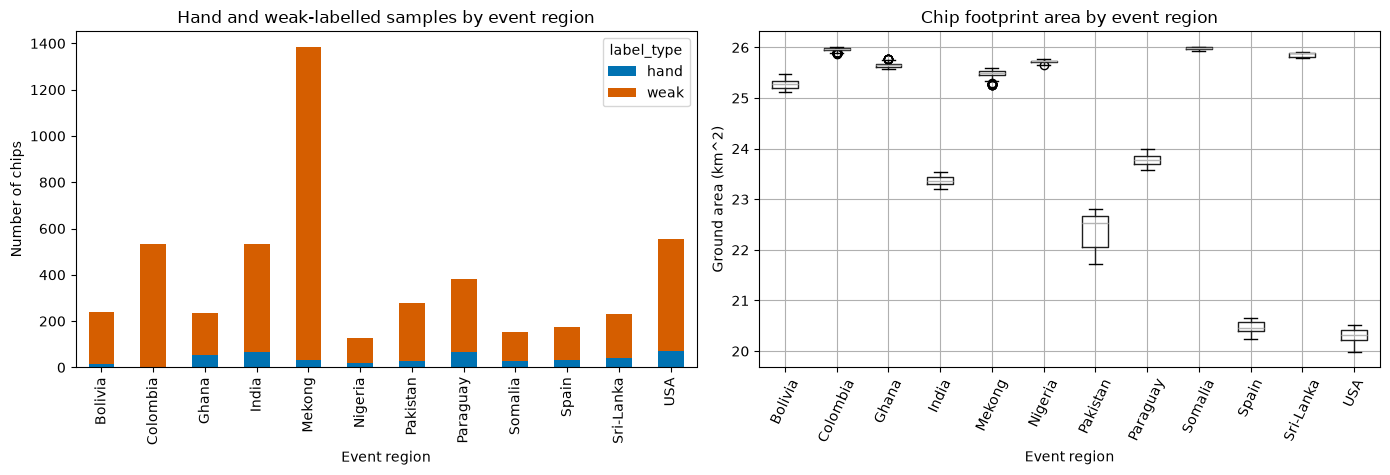

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
pd.crosstab(chips.event_region, chips.label_type).reindex(columns=['hand', 'weak'], fill_value=0).plot.bar(stacked=True, ax=axes[0], color=['#0072B2', '#D55E00'])
axes[0].set(title='Hand and weak-labelled samples by event region', ylabel='Number of chips', xlabel='Event region')
chips.boxplot(column='area_km2', by='event_region', ax=axes[1], rot=65)
axes[1].set(title='Chip footprint area by event region', ylabel='Ground area (km^2)', xlabel='Event region')
fig.suptitle('')
fig.tight_layout()
plt.show()
# EPSG:4326 chips have angular pixel spacing, so their physical width varies with latitude.

In [7]:
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
(OUTPUT_DIR / 'world_map.html').write_text(map_html, encoding='utf-8')
(OUTPUT_DIR / 'chip_footprints.geojson').write_text(json.dumps(collection, indent=2, allow_nan=False), encoding='utf-8')
chips.to_csv(OUTPUT_DIR / 'chip_inventory.csv', index=False)
event_summary.to_csv(OUTPUT_DIR / 'event_summary.csv')
pd.DataFrame(split_audit).to_csv(OUTPUT_DIR / 'split_audit.csv', index=False)
fig.savefig(OUTPUT_DIR / 'coverage_summary.png', dpi=180, bbox_inches='tight')
print('Saved map, footprints, tables and summary figure to:', OUTPUT_DIR)
print('Open world_map.html in a browser if the notebook renderer blocks the interactive map.')

Saved map, footprints, tables and summary figure to: d:\UNI\GeoTest\outputs\sen1floods11_geographic_coverage
Open world_map.html in a browser if the notebook renderer blocks the interactive map.
